## 1. Loading data

In [5]:
# Import packages
import os              
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd

In [31]:
# Import fire perimeter
perimeter = gpd.read_file(os.path.join('data','fire25_1.gdb'))

# Read in netCDF file
landsat = xr.open_dataset(os.path.join('data','landsat8-2025-02-23-palisades-eaton.nc'))

sh: 1: getfattr: not found


## Fire perimeter data exploration 
[Metadata](https://calfire-forestry.maps.arcgis.com/home/item.html?id=a31aa1efe1d6466f8530b501c30ab00a#overview)

<Axes: >

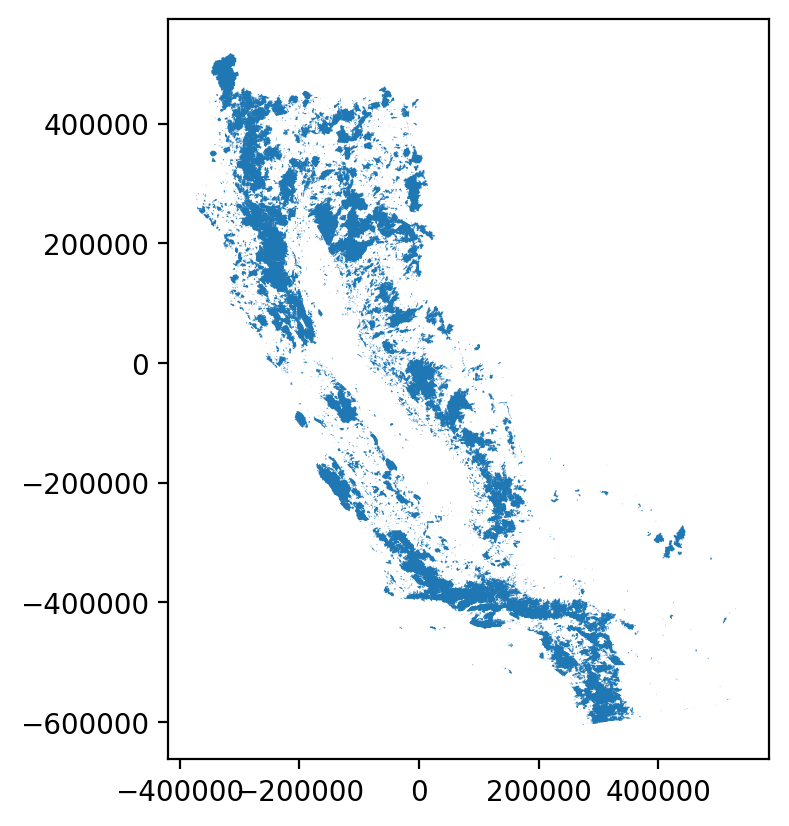

In [14]:
perimeter.plot()

In [15]:
# Check CRS
perimeter.crs

<Projected CRS: EPSG:3310>
Name: NAD83 / California Albers
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: United States (USA) - California.
- bounds: (-124.45, 32.53, -114.12, 42.01)
Coordinate Operation:
- name: California Albers
- method: Albers Equal Area
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [16]:
# Check first 5 rows
perimeter.head()

,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,IRWINID,ALARM_DATE,CONT_DATE,C_METHOD,CAUSE,OBJECTIVE,COMPLEX_ID,COMPLEX_NAME,COMMENTS,FIRE_NUM,Shape_Length,Shape_Area,GlobalID,geometry
0,2025.0,CA,USF,LPF,GIFFORD,00002181,{08A6358F-8301-4093-9988-E265C8F6F0A9},2025-08-01 00:00:00+00:00,2025-10-14 00:00:00+00:00,3,14,1.0,None,None,None,None,257388.320379,5.326211e+08,{E87207FF-BD3D-4836-8A89-AD218A20B17E},"MULTIPOLYGON (((-35131.146 -302750.005, -35107..."
1,2025.0,CA,USF,LPF,MADRE,00001817,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},2025-07-02 00:00:00+00:00,2025-07-26 00:00:00+00:00,7,14,1.0,None,None,None,None,191846.167384,3.269014e+08,{C59C71E2-F79F-440B-8C84-48058988F3CF},"MULTIPOLYGON (((-4405.284 -313794.721, -4405.4..."
2,2025.0,CA,USF,SNF,GARNET,00001684,{68B988A1-C190-4F0C-9BEA-A658D389D167},2025-08-24 00:00:00+00:00,2025-10-23 00:00:00+00:00,3,1,1.0,None,None,None,None,234717.355087,2.428892e+08,{DDD0B278-7655-4F20-829D-FEEEF1DC935F},"MULTIPOLYGON (((89617.826 -122364.580, 89614.9..."
3,2025.0,CA,CDF,FKU,SALT,00018739,{7F4A1474-6439-44F3-8F0D-083DCFD33639},2025-09-02 00:00:00+00:00,2025-09-17 00:00:00+00:00,7,1,1.0,None,None,Park incident clipped out per BEU,None,90080.360959,1.034115e+08,{6817A72C-90CF-4CD4-8F26-2B9622F1F140},"MULTIPOLYGON (((-31970.799 -229822.278, -31947..."
4,2025.0,CA,CDF,LDF,PALISADES,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07 00:00:00+00:00,2025-01-31 00:00:00+00:00,7,14,1.0,None,None,None,None,116028.197349,9.489426e+07,{73730F90-5D60-4850-98C2-2431C4284CD7},"MULTIPOLYGON (((136696.228 -441776.379, 136683..."


In [29]:
# Check datatypes
perimeter.dtypes

year                        float64
state                        object
agency                       object
unit_id                      object
fire_name                    object
inc_num                      object
irwinid                      object
alarm_date      datetime64[ns, UTC]
cont_date       datetime64[ns, UTC]
c_method                      int64
cause                         int64
objective                   float64
complex_id                   object
complex_name                 object
comments                     object
fire_num                     object
shape_length                float64
shape_area                  float64
globalid                     object
geometry                   geometry
dtype: object

The data is inclusive for California only. The CRS is EPSG:3310, and is geographic. I will be projecting the Landsat data to match the fire perimeter.

In [24]:
# Clean the data
perimeter.columns = perimeter.columns.str.lower()
perimeter.rename(columns={'year_':'year'}, inplace=True)
perimeter.columns

Index(['year', 'state', 'agency', 'unit_id', 'fire_name', 'inc_num', 'irwinid', 'alarm_date',
       'cont_date', 'c_method', 'cause', 'objective', 'complex_id', 'complex_name', 'comments',
       'fire_num', 'shape_length', 'shape_area', 'globalid', 'geometry'],
      dtype='object')

In [28]:
# Subset for Eaton and Palisades in 2025
eaton_perimeter = perimeter[(perimeter['fire_name'] == 'EATON') & (perimeter['year'] == 2025)]
palisades_perimeter = perimeter[(perimeter['fire_name'] == 'PALISADES') & (perimeter['year'] == 2025)]

## 3. Landsat data exploration


In [30]:
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...